# Glacier Album: EIC Messages and Source Data

Issues #8 (exploration) and #17 (tracks). Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md).

**The album's message, in EIC's words** ([5235](https://svs.gsfc.nasa.gov/5235/)): "As the planet warms and polar ice melts, our global average sea level is rising."

**The story this notebook checks, in the source data:**

1. **Breathing** (context only): polar sea ice freezes and thaws every year. The album leaves this cycle out and plays one value per year, so the long-term change stays audible.
2. **Melting on average**: under that yearly rhythm, the ice keeps shrinking year after year.
3. **Loss**: in 2024 the Arctic melted well below the 1981–2010 normal.
4. **Consequence**: the sea rises.
5. **Response**: coastal cities plan for it.

Sections 9 to 11 turn this into the album's two tracks, North and South. Each plays one pole's sea ice together with the global sea level, and both are exported to `data/glacier/tracks/`.

Every link used is listed in section 1, so you can check any number against its source.

Run with `npm run notebook`. Downloads go to `data/glacier/raw/` (local only). Every source is public; no login is needed.

In [1]:
import html
import json
import re
from datetime import date
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import shapely
from IPython.display import Markdown, display
from pyproj import Transformer
from shapely import affinity
from shapely.geometry import LineString, MultiLineString, MultiPolygon, Polygon, box, mapping
from shapely.ops import unary_union

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/glacier/raw")
TRACKS = Path("../data/glacier/tracks")
(RAW / "api").mkdir(parents=True, exist_ok=True)


def download(name, url, session=None):
    """Download url into data/glacier/raw once and return the local path."""
    path = RAW / name
    if not path.exists():
        response = (session or requests).get(url, timeout=120)
        response.raise_for_status()
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(response.content)
    return path


def svs_page(page_id):
    return json.loads(download(f"api/{page_id}.json", f"https://svs.gsfc.nasa.gov/api/{page_id}").read_text())


def plain(text):
    return html.unescape(re.sub(r"<[^>]+>", "", text or "")).strip()


def source_note(ax, text):
    ax.annotate(text, xy=(0, -0.22), xycoords="axes fraction", fontsize=8, color="gray")

## 1. Links

Everything this notebook reads, in one place. The tables are built from the SVS API, so they stay correct if EIC changes.

### 1.1 Where each visualization sits in the EIC gallery

In [2]:
EIC_GALLERY = 40467
PAGES = [5046, 5064, 5099, 5382, 5235, 14713]


def gallery_paths(gallery_id):
    """Map each page id to the gallery sections that lead to it from the EIC gallery."""
    paths = {}

    def walk(page_id, trail):
        page = svs_page(page_id)
        if page.get("page_type") != "Gallery":
            paths.setdefault(page_id, []).append(trail)
            return
        for group in page.get("media_groups", []):
            for item in group.get("items", []):
                inst = item.get("instance") or {}
                if item["type"] in ("gallery_page", "details_page") and inst.get("id"):
                    step = f"{group['title']} → [{inst['title']}]({inst['url'].replace('http://', 'https://')})"
                    if inst.get("page_type") == "Gallery" and inst["id"] not in [t[0] for t in trail]:
                        walk(inst["id"], trail + [(inst["id"], step)])
                    elif inst.get("page_type") != "Gallery":
                        paths.setdefault(inst["id"], []).append(trail + [(inst["id"], step)])

    walk(gallery_id, [])
    return paths


paths = gallery_paths(EIC_GALLERY)
rows = ["| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |", "| --- | --- |"]
for page_id in PAGES:
    trails = {" › ".join(step for _, step in trail) for trail in paths.get(page_id, [])}
    rows.append(f"| [{page_id}](https://svs.gsfc.nasa.gov/{page_id}/) | {'<br>'.join(sorted(trails))} |")
display(Markdown("\n".join(rows)))

| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |
| --- | --- |
| [5046](https://svs.gsfc.nasa.gov/5046/) | Daily Visualizations → [Daily Visualizations](https://svs.gsfc.nasa.gov/gallery/daily-visualizations/) › Visualizations → [Daily Arctic Sea Ice, By Year](https://svs.gsfc.nasa.gov/5046/) |
| [5064](https://svs.gsfc.nasa.gov/5064/) | Daily Visualizations → [Daily Visualizations](https://svs.gsfc.nasa.gov/gallery/daily-visualizations/) › Visualizations → [Daily Antarctic Sea Ice, By Year](https://svs.gsfc.nasa.gov/5064/) |
| [5099](https://svs.gsfc.nasa.gov/5099/) | Daily Visualizations → [Daily Visualizations](https://svs.gsfc.nasa.gov/gallery/daily-visualizations/) › Visualizations → [Daily Polar Sea Ice, Two Year History](https://svs.gsfc.nasa.gov/5099/)<br>EIC Dashboards → [Climate Vital Signs Dashboard](https://svs.gsfc.nasa.gov/gallery/climate-vital-signs-dashboard/) › Visualizations → [Daily Polar Sea Ice, Two Year History](https://svs.gsfc.nasa.gov/5099/) |
| [5382](https://svs.gsfc.nasa.gov/5382/) | EIC Dashboards → [Climate Vital Signs Dashboard](https://svs.gsfc.nasa.gov/gallery/climate-vital-signs-dashboard/) › Visualizations → [Arctic Sea Ice Minimum 2024](https://svs.gsfc.nasa.gov/5382/) |
| [5235](https://svs.gsfc.nasa.gov/5235/) | EIC Dashboards → [Climate Vital Signs Dashboard](https://svs.gsfc.nasa.gov/gallery/climate-vital-signs-dashboard/) › Visualizations → [Sea Level Through a Porthole (2023)](https://svs.gsfc.nasa.gov/5235/) |
| [14713](https://svs.gsfc.nasa.gov/14713/) | EIC Videos → [Building Coastal Resilience with NASA Data](https://svs.gsfc.nasa.gov/14713/) |

### 1.2 What each page cites, and what this notebook downloads

- **Cited by EIC** comes from the `datasets` field of each SVS page, as published.
- **Downloaded here** is the file this notebook actually reads.
- When EIC gives no download link, we use a substitute and say why.

In [3]:
def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets", []):
        name = f"{d['name']} ({d.get('sensor') or d.get('platform')})"
        out.append(f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link")
    return "<br>".join(out) or "none"


NSIDC = "https://noaadata.apps.nsidc.org/NOAA/G02135"
STAR_FILE = "slr_sla_gbl_free_ref_90.csv"
STAR_URL = f"https://www.star.nesdis.noaa.gov/socd/lsa/SeaLevelRise/slr/{STAR_FILE}"
STAR_PAGE = "https://www.star.nesdis.noaa.gov/socd/lsa/SeaLevelRise/"
SEA_ICE_FILES = (f"[Arctic daily]({NSIDC}/north/daily/data/N_seaice_extent_daily_v4.0.csv), "
                 f"[Antarctic daily]({NSIDC}/south/daily/data/S_seaice_extent_daily_v4.0.csv), "
                 f"[Arctic 1981–2010]({NSIDC}/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), "
                 f"[Antarctic 1981–2010]({NSIDC}/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv), "
                 f"[Arctic September]({NSIDC}/north/monthly/data/N_09_extent_v4.0.csv), "
                 f"[Antarctic February]({NSIDC}/south/monthly/data/S_02_extent_v4.0.csv), "
                 f"monthly extent polygons ([Arctic]({NSIDC}/north/monthly/shapefiles/shp_extent/09_Sep/), "
                 f"[Antarctic]({NSIDC}/south/monthly/shapefiles/shp_extent/02_Feb/)), "
                 f"1981–2010 median ice edges ([Arctic]({NSIDC}/north/monthly/shapefiles/shp_median/), "
                 f"[Antarctic]({NSIDC}/south/monthly/shapefiles/shp_median/))")
DOWNLOADED = {
    "sea ice": ("[NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): " + SEA_ICE_FILES,
                "Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account "
                "and start in 2012. NSIDC is the source of the numbers EIC quotes in 5382, and its recent values "
                "come from the same AMSR2 sensor. Public."),
    "sea level": (f"[NOAA Laboratory for Satellite Altimetry, global mean sea level]({STAR_PAGE}): [{STAR_FILE}]({STAR_URL})",
                  "Substitute. EIC cites [GSFC GMSL v5.1](https://podaac.jpl.nasa.gov/dataset/MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V51) "
                  "([DOI 10.5067/GMSLM-TJ151](https://doi.org/10.5067/GMSLM-TJ151)), which needs an Earthdata login. "
                  "NOAA uses the same altimeter missions (TOPEX/Poseidon, Jason-1/2/3, Sentinel-6MF). Public."),
}
KIND = {5046: "sea ice", 5064: "sea ice", 5099: "sea ice", 5382: "sea ice", 5235: "sea level", 14713: None}

rows = ["| SVS page | Cited by EIC | Downloaded here | Note |", "| --- | --- | --- | --- |"]
for page_id in PAGES:
    page = svs_page(page_id)
    title = f"[{page_id} {page['title']}](https://svs.gsfc.nasa.gov/{page_id}/) ([API](https://svs.gsfc.nasa.gov/api/{page_id}))"
    kind = KIND[page_id]
    used, note = DOWNLOADED[kind] if kind else ("nothing", "Produced video. Message only; its imagery may not be remixed.")
    rows.append(f"| {title} | {cited(page_id)} | {used} | {note} |")
display(Markdown("\n".join(rows)))

| SVS page | Cited by EIC | Downloaded here | Note |
| --- | --- | --- | --- |
| [5046 Daily Arctic Sea Ice, By Year](https://svs.gsfc.nasa.gov/5046/) ([API](https://svs.gsfc.nasa.gov/api/5046)) | [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/)<br>10 km Daily Sea Ice Concentration (AMSR2), no link<br>10 km Daily 89 GHz Brightness Temperature (AMSR2), no link | [NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): [Arctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_daily_v4.0.csv), [Antarctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_daily_v4.0.csv), [Arctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), [Antarctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv), [Arctic September](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/data/N_09_extent_v4.0.csv), [Antarctic February](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/data/S_02_extent_v4.0.csv), monthly extent polygons ([Arctic](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_extent/09_Sep/), [Antarctic](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/shapefiles/shp_extent/02_Feb/)), 1981–2010 median ice edges ([Arctic](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_median/), [Antarctic](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/shapefiles/shp_median/)) | Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account and start in 2012. NSIDC is the source of the numbers EIC quotes in 5382, and its recent values come from the same AMSR2 sensor. Public. |
| [5064 Daily Antarctic Sea Ice, By Year](https://svs.gsfc.nasa.gov/5064/) ([API](https://svs.gsfc.nasa.gov/api/5064)) | [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/)<br>10 km Daily Sea Ice Concentration (AMSR2), no link<br>10 km Daily 89 GHz Brightness Temperature (AMSR2), no link | [NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): [Arctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_daily_v4.0.csv), [Antarctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_daily_v4.0.csv), [Arctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), [Antarctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv), [Arctic September](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/data/N_09_extent_v4.0.csv), [Antarctic February](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/data/S_02_extent_v4.0.csv), monthly extent polygons ([Arctic](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_extent/09_Sep/), [Antarctic](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/shapefiles/shp_extent/02_Feb/)), 1981–2010 median ice edges ([Arctic](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_median/), [Antarctic](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/shapefiles/shp_median/)) | Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account and start in 2012. NSIDC is the source of the numbers EIC quotes in 5382, and its recent values come from the same AMSR2 sensor. Public. |
| [5099 Daily Polar Sea Ice, Two Year History](https://svs.gsfc.nasa.gov/5099/) ([API](https://svs.gsfc.nasa.gov/api/5099)) | [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/)<br>10 km Daily Sea Ice Concentration (AMSR2), no link<br>10 km Daily 89 GHz Brightness Temperature (AMSR2), no link | [NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): [Arctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_daily_v4.0.csv), [Antarctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_daily_v4.0.csv), [Arctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), [Antarctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv), [Arctic September](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/data/N_09_extent_v4.0.csv), [Antarctic February](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/data/S_02_extent_v4.0.csv), monthly extent polygons ([Arctic](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_extent/09_Sep/), [Antarctic](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/shapefiles/shp_extent/02_Feb/)), 1981–2010 median ice edges ([Arctic](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_median/), [Antarctic](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/shapefiles/shp_median/)) | Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account and start in 2012. NSIDC is the source of the numbers EIC quotes in 5382, and its recent values come from the same AMSR2 sensor. Public. |
| [5382 Arctic Sea Ice Minimum 2024](https://svs.gsfc.nasa.gov/5382/) ([API](https://svs.gsfc.nasa.gov/api/5382)) | [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/)<br>10 km Daily Sea Ice Concentration (AMSR2), no link<br>10 km Daily 89 GHz Brightness Temperature (AMSR2), no link | [NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): [Arctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_daily_v4.0.csv), [Antarctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_daily_v4.0.csv), [Arctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), [Antarctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv), [Arctic September](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/data/N_09_extent_v4.0.csv), [Antarctic February](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/data/S_02_extent_v4.0.csv), monthly extent polygons ([Arctic](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_extent/09_Sep/), [Antarctic](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/shapefiles/shp_extent/02_Feb/)), 1981–2010 median ice edges ([Arctic](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_median/), [Antarctic](https://noaadata.apps.nsidc.org/NOAA/G02135/south/monthly/shapefiles/shp_median/)) | Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account and start in 2012. NSIDC is the source of the numbers EIC quotes in 5382, and its recent values come from the same AMSR2 sensor. Public. |
| [5235 Sea Level Through a Porthole (2023)](https://svs.gsfc.nasa.gov/5235/) ([API](https://svs.gsfc.nasa.gov/api/5235)) | [Global Mean Sea Level (TOPEX/Poseidon, Jason-1, OSTM/Jason-2, and Jason-3)](https://podaac.jpl.nasa.gov/dataset/MERGED_TP_J1_OSTM_OST_ALL_V51) | [NOAA Laboratory for Satellite Altimetry, global mean sea level](https://www.star.nesdis.noaa.gov/socd/lsa/SeaLevelRise/): [slr_sla_gbl_free_ref_90.csv](https://www.star.nesdis.noaa.gov/socd/lsa/SeaLevelRise/slr/slr_sla_gbl_free_ref_90.csv) | Substitute. EIC cites [GSFC GMSL v5.1](https://podaac.jpl.nasa.gov/dataset/MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V51) ([DOI 10.5067/GMSLM-TJ151](https://doi.org/10.5067/GMSLM-TJ151)), which needs an Earthdata login. NOAA uses the same altimeter missions (TOPEX/Poseidon, Jason-1/2/3, Sentinel-6MF). Public. |
| [14713 Building Coastal Resilience with NASA Data](https://svs.gsfc.nasa.gov/14713/) ([API](https://svs.gsfc.nasa.gov/api/14713)) | none | nothing | Produced video. Message only; its imagery may not be remixed. |

## 2. What EIC says

The message of each page, taken from its description (or its longest caption when the description is only a heading).

In [4]:
def message(page_id):
    page = svs_page(page_id)
    text = plain(page["description"].split(" || ")[0])
    if len(text) < 100:
        texts = [plain(g.get("caption")) or plain(g.get("description")) for g in page["media_groups"]]
        text = max(texts, key=len)
    return text


display(Markdown("\n\n".join(f"**[{i}](https://svs.gsfc.nasa.gov/{i}/) {svs_page(i)['title']}**\n\n> {message(i)[:700]}"
                               for i in PAGES)))

**[5046](https://svs.gsfc.nasa.gov/5046/) Daily Arctic Sea Ice, By Year**

> This visualization shows the daily Arctic sea ice and seasonal land cover change progressing through time, with a single frame rendered for each day (available from the drop-down of each image window), and an animation created from these frames. The Japan Aerospace Exploration Agency (JAXA) provides many water-related products derived from data acquired by the Advanced Microwave Scanning Radiometer 2 (AMSR2) instrument aboard the Global Change Observation Mission 1st-Water "SHIZUKU" (GCOM-W1) satellite. Two JAXA datasets are used in this animation:  the 10-km daily sea ice concentration and the 10 km daily 89 GHz Brightness Temperature.In this visualization sea ice changes from day to day, w

**[5064](https://svs.gsfc.nasa.gov/5064/) Daily Antarctic Sea Ice, By Year**

> This visualization shows the daily Antarctic sea ice and seasonal land cover change progressing through time, with a single frame rendered for each day (available from the drop-down of each image window), and an animation created from these frames. The Japan Aerospace Exploration Agency (JAXA) provides many water-related products derived from data acquired by the Advanced Microwave Scanning Radiometer 2 (AMSR2) instrument aboard the Global Change Observation Mission 1st-Water "SHIZUKU" (GCOM-W1) satellite. Two JAXA datasets are used in this animation:  the 10-km daily sea ice concentration and the 10 km daily 89 GHz Brightness Temperature.In this visualization sea ice changes from day to day

**[5099](https://svs.gsfc.nasa.gov/5099/) Daily Polar Sea Ice, Two Year History**

> This visualization shows the daily Arctic and Antarctic sea ice and seasonal land cover change over a two-year history from the present, with a single frame rendered for each day (available from the drop-down of each image window), and an animation created from these frames, The Japan Aerospace Exploration Agency (JAXA) provides many water-related products derived from data acquired by the Advanced Microwave Scanning Radiometer 2 (AMSR2) instrument aboard the Global Change Observation Mission 1st-Water "SHIZUKU" (GCOM-W1) satellite. Two JAXA datasets are used in this animation: the 10-km daily sea ice concentration and the 10 km daily 89 GHz Brightness Temperature.In this visualization sea i

**[5382](https://svs.gsfc.nasa.gov/5382/) Arctic Sea Ice Minimum 2024**

> Satellite-based passive microwave images of the sea ice have provided a reliable tool for continuously monitoring changes in the Arctic ice since 1979. Every summer the Arctic ice cap melts down to what scientists call its "minimum" before colder weather begins to cause ice cover to increase. An analysis of satellite data by NASA and the National Snow and Ice Data Center (NSIDC) at the University of Colorado Boulder shows that the 2024 minimum extent, which was likely reached on Sept. 11, measured 1.65 million square miles (4.28 million square kilometers). This is the 7th lowest measured sea ice extent for the arctic on record.The Japan Aerospace Exploration Agency (JAXA) provides many water

**[5235](https://svs.gsfc.nasa.gov/5235/) Sea Level Through a Porthole (2023)**

> As the planet warms and polar ice melts, our global average sea level is rising. Although exact ocean heights vary due to local geography, climate over time, and dynamic fluid interactions with gravity and planetary rotation, scientists observe sea level trends by comparing measurements against a 20 year spatial and temporal mean reference. These visualizations use the visual metaphor of a submerged porthole window to observe how far our oceans rose between 1993 and 2023.

**[14713](https://svs.gsfc.nasa.gov/14713/) Building Coastal Resilience with NASA Data**

> The city of Mobile, AL is working with NASA’s Sea Level Change Team to plan for future infrastructure projects and to protect Mobile’s coastal resources. As sea levels change globally, coastal cities feel the effects of more frequent and more severe storms and flooding. NASA’s sea level change data helps Mobile and other coastal communities plan for a more resilient future.

## 3. Source data: sea ice extent

**NSIDC Sea Ice Index v4.0** ([dataset page](https://nsidc.org/data/g02135)). Links to each file are in section 1.2.

- **Extent**: area of ocean with at least 15% ice cover, in million km²
- **Daily**, Oct 1978 to now (every other day before Aug 1987)
- **1981–2010 climatology**: the "normal" EIC compares against, per day of year

Credit: Fetterer, F., et al. Sea Ice Index, Version 4. NSIDC. [doi:10.7265/a98x-0f50](https://doi.org/10.7265/a98x-0f50)

> **Sea ice is not glacier ice.** Sea ice is frozen seawater floating on the ocean. When it melts it barely changes sea level, because it already displaces its own weight of water. Sea level rises when **land ice** melts (glaciers and the ice sheets of Greenland and Antarctica) and when seawater warms and expands. Sea ice decline and sea level rise are both signs of the same warming, which is why EIC shows them side by side.

In [5]:
POLE = {"N": "north", "S": "south"}
NAME = {"N": "Arctic", "S": "Antarctic"}


def sea_ice_daily(h):
    name = f"{h}_seaice_extent_daily_v4.0.csv"
    path = download(name, f"{NSIDC}/{POLE[h]}/daily/data/{name}")
    df = pd.read_csv(path, skiprows=[1], skipinitialspace=True, usecols=[0, 1, 2, 3])
    df.columns = ["year", "month", "day", "extent"]
    df["date"] = pd.to_datetime(df[["year", "month", "day"]])
    # Fill single missing days (every other day before 1987) so rolling averages work.
    return df.set_index("date")["extent"].asfreq("D").interpolate(limit=2)


def sea_ice_normal(h):
    name = f"{h}_seaice_extent_climatology_1981-2010_v4.0.csv"
    path = download(name, f"{NSIDC}/{POLE[h]}/daily/data/{name}")
    df = pd.read_csv(path, skiprows=1, skipinitialspace=True)
    df.columns = ["doy", "mean", "std", "p10", "p25", "p50", "p75", "p90"]
    return df.set_index("doy")


ice = {h: sea_ice_daily(h) for h in "NS"}
normal = {h: sea_ice_normal(h) for h in "NS"}
FULL_YEARS = range(1979, ice["N"].index.max().year)  # complete years only
print({NAME[h]: f"{s.index.min().date()} to {s.index.max().date()}" for h, s in ice.items()})

{'Arctic': '1978-10-26 to 2026-11-12', 'Antarctic': '1978-10-26 to 2026-11-12'}


## 4. Message 1, breathing: the poles freeze and thaw every year

[5046](https://svs.gsfc.nasa.gov/5046/), [5064](https://svs.gsfc.nasa.gov/5064/), [5099](https://svs.gsfc.nasa.gov/5099/)

> "This visualization shows the daily Arctic sea ice and seasonal land cover change progressing through time, with a single frame rendered for each day."

EIC shows 2021 to 2024. Same years from the source data, against the 1981–2010 normal:

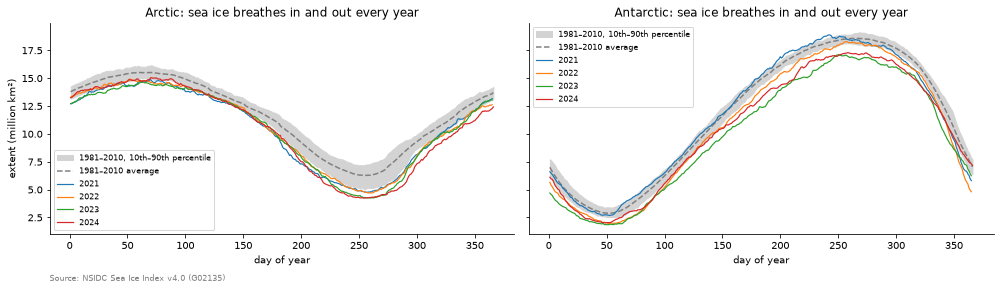

In [6]:
YEARS = [2021, 2022, 2023, 2024]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, h in zip(axes, "NS"):
    norm = normal[h]
    ax.fill_between(norm.index, norm["p10"], norm["p90"], color="lightgray", label="1981–2010, 10th–90th percentile")
    ax.plot(norm.index, norm["mean"], color="gray", linestyle="--", label="1981–2010 average")
    for year in YEARS:
        s = ice[h][str(year)]
        ax.plot(s.index.day_of_year, s.values, linewidth=1.2, label=str(year))
    ax.set_title(f"{NAME[h]}: sea ice breathes in and out every year")
    ax.set_xlabel("day of year")
    ax.legend(fontsize=8)
axes[0].set_ylabel("extent (million km²)")
source_note(axes[0], "Source: NSIDC Sea Ice Index v4.0 (G02135)")
plt.tight_layout()

In [7]:
def yearly_cycle(h, years):
    f5 = ice[h].rolling(5).mean()  # NSIDC reports minima and maxima on a 5-day trailing average
    f5 = f5[f5.index.year.isin(years)]
    g = f5.groupby(f5.index.year)
    out = pd.DataFrame({"max": g.max(), "max date": g.idxmax().dt.strftime("%b %d"),
                        "min": g.min(), "min date": g.idxmin().dt.strftime("%b %d")})
    out["swing (max - min)"] = out["max"] - out["min"]
    return out.round(2)


pd.concat({NAME[h]: yearly_cycle(h, YEARS) for h in "NS"})

max max date   min min date  swing (max - min)
          date                                                  
Arctic    2021  14.78   Mar 12  4.77   Sep 16              10.01
          2022  14.84   Feb 25  4.70   Sep 19              10.14
          2023  14.62   Mar 06  4.26   Sep 19              10.36
          2024  15.02   Mar 14  4.25   Sep 14              10.77
Antarctic 2021  18.84   Sep 01  2.70   Feb 24              16.14
          2022  18.25   Sep 16  1.98   Feb 25              16.27
          2023  17.07   Sep 09  1.85   Feb 21              15.21
          2024  17.26   Sep 16  2.03   Feb 20              15.23

- Every year the Arctic swings by about 10 million km² and the Antarctic by 15 to 16 million km².
- The poles breathe in **opposite phase**: the Arctic peaks in March and bottoms out in September, the Antarctic the other way round.
- Over four years the yearly rhythm dominates. To see the trend, step back to the whole record (next section).

## 5. Message 2, melting on average: the ice keeps shrinking

The yearly rhythm hides a slow decline. Averaging each year removes the seasons and leaves the trend. This section is our computation from the source data; it backs EIC's message that "polar ice melts" ([5235](https://svs.gsfc.nasa.gov/5235/)).

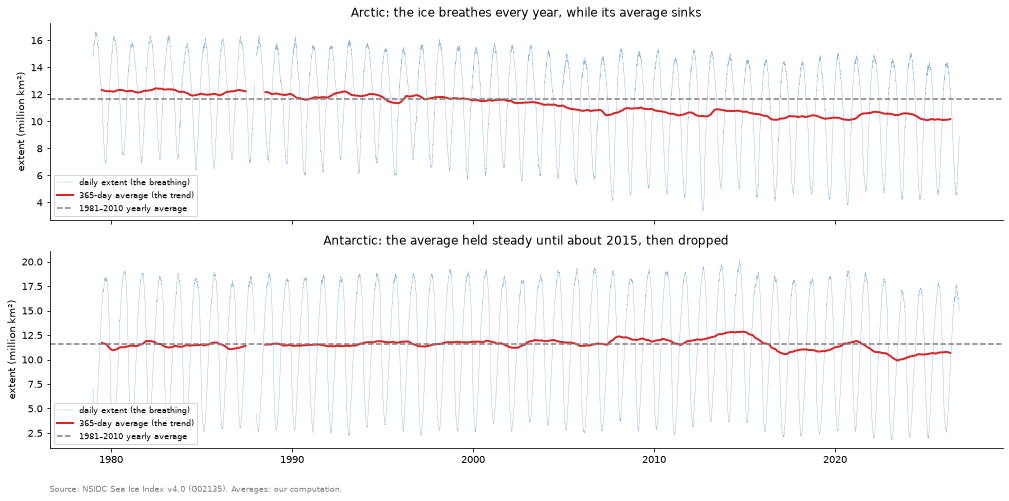

In [8]:
TITLES = {"N": "Arctic: the ice breathes every year, while its average sinks",
          "S": "Antarctic: the average held steady until about 2015, then dropped"}
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, h in zip(axes, "NS"):
    s = ice[h]["1979":]
    yearly = s.rolling(365, center=True).mean()
    ax.plot(s.index, s.values, color="tab:blue", linewidth=0.4, alpha=0.5, label="daily extent (the breathing)")
    ax.plot(yearly.index, yearly.values, color="tab:red", linewidth=2, label="365-day average (the trend)")
    ax.axhline(normal[h]["mean"].mean(), color="gray", linestyle="--", label="1981–2010 yearly average")
    ax.set_title(TITLES[h])
    ax.set_ylabel("extent (million km²)")
    ax.legend(fontsize=8, loc="lower left")
source_note(axes[1], "Source: NSIDC Sea Ice Index v4.0 (G02135). Averages: our computation.")
plt.tight_layout()

,1979–1988 average,2016–2025 average,change (%),lowest year
Arctic,12.19,10.35,-15.13,2025
Antarctic,11.48,10.88,-5.27,2023
Both poles,23.67,21.22,-10.35,2023


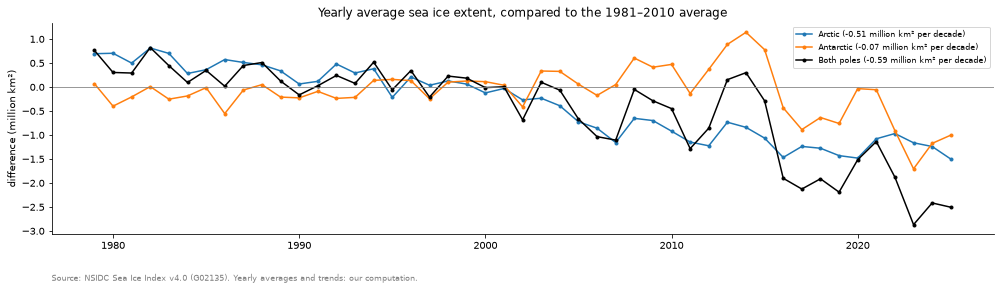

In [9]:
annual = pd.DataFrame({NAME[h]: ice[h].groupby(ice[h].index.year).mean() for h in "NS"}).loc[FULL_YEARS]
annual["Both poles"] = annual["Arctic"] + annual["Antarctic"]

fig, ax = plt.subplots(figsize=(14, 4.2))
for col, color in [("Arctic", "tab:blue"), ("Antarctic", "tab:orange"), ("Both poles", "black")]:
    anomaly = annual[col] - annual.loc[1981:2010, col].mean()
    trend = np.polyfit(anomaly.index, anomaly.values, 1)
    ax.plot(anomaly.index, anomaly.values, marker="o", markersize=3, color=color,
            label=f"{col} ({trend[0] * 10:+.2f} million km² per decade)")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Yearly average sea ice extent, compared to the 1981–2010 average")
ax.set_ylabel("difference (million km²)")
ax.legend(fontsize=8)
source_note(ax, "Source: NSIDC Sea Ice Index v4.0 (G02135). Yearly averages and trends: our computation.")
plt.tight_layout()

change = pd.DataFrame({
    "1979–1988 average": annual.loc[1979:1988].mean(),
    f"{FULL_YEARS[-1] - 9}–{FULL_YEARS[-1]} average": annual.loc[FULL_YEARS[-1] - 9:].mean(),
})
change["change (%)"] = (change.iloc[:, 1] / change.iloc[:, 0] - 1) * 100
change["lowest year"] = annual.idxmin()
change.round(2)

What the data says:

- **Arctic**: a steady decline since 1979. The last ten years average about 15% less ice than the first ten.
- **Antarctic**: no decline until about 2015, then a sharp drop; 2023 is its lowest year on record. The two poles do not change the same way.
- **Both poles together**: less ice than the 1981–2010 average in every recent year.

**Track data**: the 365-day average per pole (one value per day since 1979), or the yearly averages (one value per year). Played under the daily breathing, it becomes a floor that slowly sinks.

## 6. Message 3, loss: the Arctic melts below the old normal

[5382](https://svs.gsfc.nasa.gov/5382/)

> "Every summer the Arctic ice cap melts down to what scientists call its 'minimum' [...] the 2024 minimum extent, which was likely reached on Sept. 11, measured 1.65 million square miles (4.28 million square kilometers). This is the 7th lowest measured sea ice extent for the arctic on record. [...] The yellow boundary shows the minimum extent averaged over the 30-year period from 1981 to 2010."

The animation runs from the 2024 maximum (March 14) to the minimum (Sept 11).

Gap to the 1981–2010 average: 0.46 million km² on Mar 14, 2.01 on Sep 11, largest 2.17


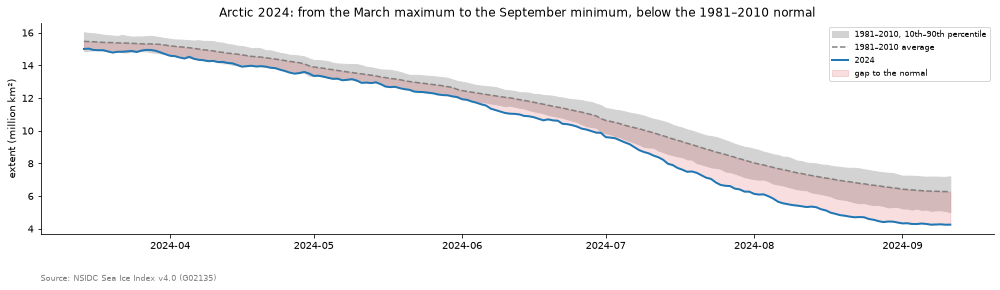

In [10]:
melt = ice["N"]["2024-03-14":"2024-09-11"]
norm = normal["N"].loc[melt.index.day_of_year]
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.fill_between(melt.index, norm["p10"], norm["p90"], color="lightgray", label="1981–2010, 10th–90th percentile")
ax.plot(melt.index, norm["mean"].values, color="gray", linestyle="--", label="1981–2010 average")
ax.plot(melt.index, melt.values, color="tab:blue", linewidth=2, label="2024")
ax.fill_between(melt.index, melt.values, norm["mean"].values, color="tab:red", alpha=0.15, label="gap to the normal")
ax.set_title("Arctic 2024: from the March maximum to the September minimum, below the 1981–2010 normal")
ax.set_ylabel("extent (million km²)")
ax.legend(fontsize=8)
source_note(ax, "Source: NSIDC Sea Ice Index v4.0 (G02135)")
plt.tight_layout()

gap = norm["mean"].values - melt.values
print(f"Gap to the 1981–2010 average: {gap[0]:.2f} million km² on Mar 14, {gap[-1]:.2f} on Sep 11, largest {gap.max():.2f}")

,"EIC (5382, Sept 2024)",NSIDC v4.0 (this notebook)
2024 minimum,4.28 million km²,4.25 million km²
date,Sept 11,Sep 14
rank since 1979,7th lowest,6th lowest


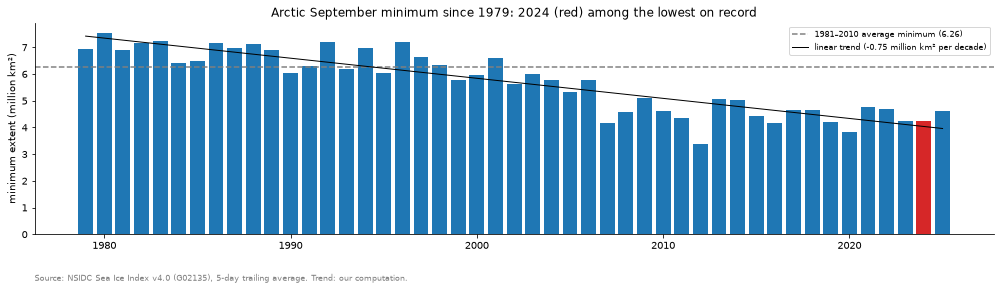

In [11]:
f5 = ice["N"].rolling(5).mean()
minima = f5.groupby(f5.index.year).agg(["min", "idxmin"]).loc[FULL_YEARS]
minima.columns = ["minimum", "date"]
minima["rank (1 = lowest)"] = minima["minimum"].rank().astype(int)
normal_min = normal["N"]["mean"].min()

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.bar(minima.index, minima["minimum"], color=["tab:red" if y == 2024 else "tab:blue" for y in minima.index])
ax.axhline(normal_min, color="gray", linestyle="--", label=f"1981–2010 average minimum ({normal_min:.2f})")
trend = np.polyfit(minima.index, minima["minimum"], 1)
ax.plot(minima.index, np.polyval(trend, minima.index), color="black", linewidth=1,
        label=f"linear trend ({trend[0] * 10:+.2f} million km² per decade)")
ax.set_title("Arctic September minimum since 1979: 2024 (red) among the lowest on record")
ax.set_ylabel("minimum extent (million km²)")
ax.legend(fontsize=8)
source_note(ax, "Source: NSIDC Sea Ice Index v4.0 (G02135), 5-day trailing average. Trend: our computation.")
plt.tight_layout()

pd.DataFrame({
    "EIC (5382, Sept 2024)": ["4.28 million km²", "Sept 11", "7th lowest"],
    "NSIDC v4.0 (this notebook)": [f"{minima.loc[2024, 'minimum']:.2f} million km²",
                                   minima.loc[2024, "date"].strftime("%b %d"),
                                   f"{minima.loc[2024, 'rank (1 = lowest)']}th lowest"],
}, index=["2024 minimum", "date", "rank since 1979"])

- 2024 stays below the normal for the whole melt season, and the gap widens toward September.
- Our numbers differ slightly from EIC's: NSIDC reprocessed the Sea Ice Index (version 4.0) after the September 2024 announcement. The message holds: 2024 is one of the lowest years on record.

**Track data**: the 2024 melt (182 days) together with the normal for the same days, so the gap can be heard. Or the yearly minimum since 1979 as a slow descending line.

## 7. Message 4, consequence: the sea rises

[5235](https://svs.gsfc.nasa.gov/5235/), [NOAA LSA sea level](https://www.star.nesdis.noaa.gov/socd/lsa/SeaLevelRise/)

> "As the planet warms and polar ice melts, our global average sea level is rising. [...] These visualizations use the visual metaphor of a submerged porthole window to observe how far our oceans rose between 1993 and 2023."
>
> "The blue mark on the ruler shows the exact measurements [...]. The level of the animated water changes more smoothly, driven by a 60-day floating average of the same data."

**Source used: NOAA Laboratory for Satellite Altimetry, global mean sea level** ([page](https://www.star.nesdis.noaa.gov/socd/lsa/SeaLevelRise/), [CSV](https://www.star.nesdis.noaa.gov/socd/lsa/SeaLevelRise/slr/slr_sla_gbl_free_ref_90.csv)). The same satellite altimeters as the dataset EIC cites: TOPEX/Poseidon, Jason-1, Jason-2, Jason-3 and Sentinel-6MF. One value about every 10 days, in mm, with the annual cycle removed.

**Why a substitute**: EIC cites NASA GSFC Global Mean Sea Level v5.1 ([PO.DAAC](https://podaac.jpl.nasa.gov/dataset/MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V51), [DOI](https://doi.org/10.5067/GMSLM-TJ151)), which can only be downloaded with an Earthdata login. NOAA processes the same missions on its own: it does not apply the glacial isostatic adjustment (GSFC does, about +0.3 mm per year) and uses its own reference level. The album uses only the change since 1993, so the reference level does not matter.

Credit, as NOAA asks: "Altimetry data are provided by NOAA Laboratory for Satellite Altimetry."

In [12]:
def decimal_year_to_date(t):
    year = np.floor(t).astype(int)
    days = np.where(pd.to_datetime(year.astype(str)).is_leap_year, 366, 365)
    return pd.to_datetime(year.astype(str)) + pd.to_timedelta((t - year) * days, unit="D")


def read_star(path):
    header = [line for line in path.read_text().splitlines() if line.startswith("#")]
    df = pd.read_csv(path, comment="#")
    missions = df.drop(columns="year")
    # One column per mission; each row holds the value of one mission only.
    out = pd.DataFrame({"sea_level_mm": missions.bfill(axis=1).iloc[:, 0],
                        "mission": missions.notna().idxmax(axis=1)})
    out.index = decimal_year_to_date(df["year"].to_numpy())
    return out.sort_index(), header


star, header = read_star(download(STAR_FILE, STAR_URL))
sea = star["sea_level_mm"]
print("\n".join(header))
print(f"\nSea level: {len(sea)} values, {sea.index.min().date()} to {sea.index.max().date()}")
star.groupby("mission", sort=False).apply(lambda g: pd.Series({"from": g.index.min().date(), "to": g.index.max().date(), "values": len(g)}))

#title = mean sea level anomaly global ocean (Annual signals removed) 
#institution = NOAA/Laboratory for Satellite Altimetry 
#references = NOAA Sea Level Rise (http://www.star.nesdis.noaa.gov/sod/lsa/SeaLevelRise/) and Radar Altimeter Database System (https://www.star.nesdis.noaa.gov/socd/lsa/RADS.php) 
#comment = Data use policy: In publications, presentations, or on web pages based on LSA data the following acknowledgment should be included: 'Altimetry data are provided by NOAA Laboratory for Satellite Altimetry.' 
#trend = 3.11 mm/year (no glacial isostatic adjustment correction) 

Sea level: 1557 values, 1992-12-17 to 2025-02-16


,from,to,values
mission,,,
TOPEX/Poseidon,1992-12-17,2005-09-30,438
Jason-1,2002-01-20,2013-06-16,371
Jason-2,2008-07-17,2017-05-16,313
Jason-3,2016-02-14,2025-01-08,313
Sentinel-6MF,2020-12-23,2025-02-16,122


Rise from 1993 to 2023 (yearly means): about 98 mm
Linear trend: 3.18 mm/year (NOAA states its own in the file header)
Rate in 2025 (quadratic fit, our computation): 4.4 mm/year


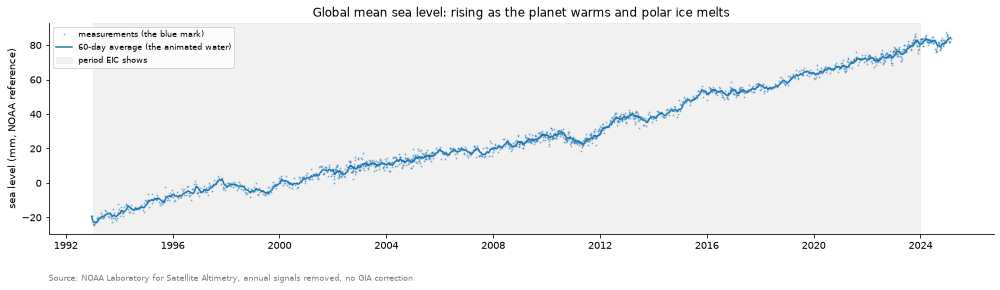

In [13]:
smooth = sea.rolling("60D").mean()
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(sea.index, sea.values, ".", markersize=2, color="tab:blue", alpha=0.4, label="measurements (the blue mark)")
ax.plot(smooth.index, smooth.values, color="tab:blue", linewidth=1.5, label="60-day average (the animated water)")
ax.axvspan(pd.Timestamp("1993-01-01"), pd.Timestamp("2023-12-31"), color="lightgray", alpha=0.3, label="period EIC shows")
ax.set_title("Global mean sea level: rising as the planet warms and polar ice melts")
ax.set_ylabel("sea level (mm, NOAA reference)")
ax.legend(fontsize=8)
source_note(ax, "Source: NOAA Laboratory for Satellite Altimetry, annual signals removed, no GIA correction")
plt.tight_layout()

rise = sea["2023"].mean() - sea["1993"].mean()
t = sea.index.year + (sea.index.day_of_year - 1) / 365.25
fit = np.polyfit(t, sea.values, 2)
print(f"Rise from 1993 to 2023 (yearly means): about {rise:.0f} mm")
print(f"Linear trend: {np.polyfit(t, sea.values, 1)[0]:.2f} mm/year (NOAA states its own in the file header)")
print(f"Rate in {t[-1]:.0f} (quadratic fit, our computation): {np.polyval(np.polyder(fit), t[-1]):.1f} mm/year")

### 7.1 Ice and sea, side by side

The same years for both: polar sea ice (sections 4–6) and global sea level. Two symptoms of one warming planet, not one causing the other (see the note in section 3).

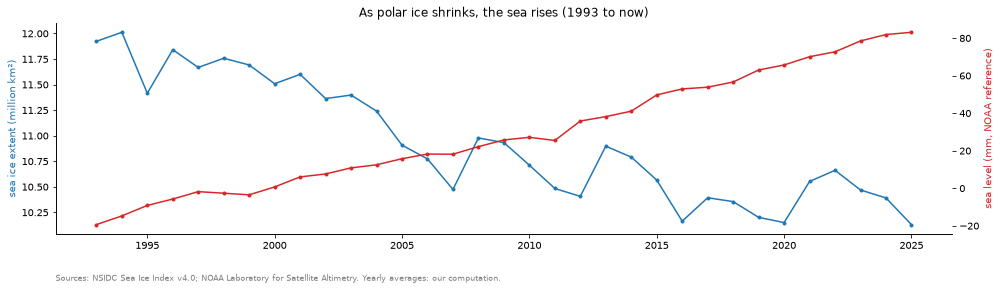

In [14]:
years = range(1993, FULL_YEARS[-1] + 1)
sea_by_year = sea.groupby(sea.index.year).mean().reindex(years)
arctic = annual["Arctic"].reindex(years)

fig, ax1 = plt.subplots(figsize=(14, 4.2))
ax1.plot(arctic.index, arctic.values, color="tab:blue", marker="o", markersize=3, label="Arctic sea ice, yearly average")
ax1.set_ylabel("sea ice extent (million km²)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(sea_by_year.index, sea_by_year.values, color="tab:red", marker="o", markersize=3, label="global mean sea level, yearly average")
ax2.set_ylabel("sea level (mm, NOAA reference)", color="tab:red")
ax1.set_title("As polar ice shrinks, the sea rises (1993 to now)")
source_note(ax1, "Sources: NSIDC Sea Ice Index v4.0; NOAA Laboratory for Satellite Altimetry. Yearly averages: our computation.")
plt.tight_layout()

**Track data**: sea level once a year, played with the sea ice of each pole in both tracks (section 9).

**Message 5, response** ([14713](https://svs.gsfc.nasa.gov/14713/)) is a produced video with no data of its own. Its imagery may not be remixed, so the album uses its message only.

> The direct cause of sea level rise, melting **glaciers and ice sheets** (land ice), is not in the EIC gallery, and NASA's GRACE ice sheet data needs an Earthdata login. The album therefore shows sea ice as the sign of polar ice melt, and never lets the amount of sea ice drive the sea level values.

## 8. Message summary

In [15]:
arctic_change = change.loc["Arctic", "change (%)"]
summary = pd.DataFrame([
    {"message": "Breathing: the poles freeze and thaw every year", "EIC pages": "5046, 5064, 5099",
     "key numbers": "yearly swing about 10 (Arctic) and 15–16 (Antarctic) million km², opposite phases",
     "source": "NSIDC Sea Ice Index v4.0"},
    {"message": "Melting on average: the ice keeps shrinking", "EIC pages": "5235 (\"polar ice melts\")",
     "key numbers": f"Arctic yearly average {arctic_change:.0f}% since 1979–1988; Antarctic lowest in "
                    f"{int(change.loc['Antarctic', 'lowest year'])}",
     "source": "NSIDC Sea Ice Index v4.0, our computation"},
    {"message": "Loss: the Arctic melts below the old normal", "EIC pages": "5382",
     "key numbers": f"2024 minimum {minima.loc[2024, 'minimum']:.2f} million km², "
                    f"{minima.loc[2024, 'rank (1 = lowest)']}th lowest since 1979; normal minimum {normal_min:.2f}",
     "source": "NSIDC Sea Ice Index v4.0"},
    {"message": "Consequence: the sea rises", "EIC pages": "5235",
     "key numbers": f"about {rise:.0f} mm from 1993 to 2023",
     "source": "NOAA LSA (substitute for GSFC GMSL v5.1)"},
    {"message": "Response: coastal cities adapt", "EIC pages": "14713", "key numbers": "-", "source": "message only"},
])
summary

,message,EIC pages,key numbers,source
0,Breathing: the poles freeze and thaw every year,"5046, 5064, 5099","yearly swing about 10 (Arctic) and 15–16 (Antarctic) million km², opposite phases",NSIDC Sea Ice Index v4.0
1,Melting on average: the ice keeps shrinking,"5235 (""polar ice melts"")",Arctic yearly average -15% since 1979–1988; Antarctic lowest in 2023,"NSIDC Sea Ice Index v4.0, our computation"
2,Loss: the Arctic melts below the old normal,5382,"2024 minimum 4.25 million km², 6th lowest since 1979; normal minimum 6.26",NSIDC Sea Ice Index v4.0
3,Consequence: the sea rises,5235,about 98 mm from 1993 to 2023,NOAA LSA (substitute for GSFC GMSL v5.1)
4,Response: coastal cities adapt,14713,-,message only


## 9. Album tracks

[5382](https://svs.gsfc.nasa.gov/5382/), [5064](https://svs.gsfc.nasa.gov/5064/), [5235](https://svs.gsfc.nasa.gov/5235/), [NSIDC monthly extent](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/data/), [NOAA LSA sea level](https://www.star.nesdis.noaa.gov/socd/lsa/SeaLevelRise/)

Decided in issue #17. Two tracks, one per pole. Each plays that pole's sea ice and the global mean sea level on the same timeline, so the listener hears the ice shrink while the sea rises: "As the planet warms and polar ice melts, our global average sea level is rising" ([5235](https://svs.gsfc.nasa.gov/5235/)).

| # | Track | Ice | Sea | Years | EIC pages |
| --- | --- | --- | --- | --- | --- |
| 1 | North | Arctic September extent, with its 1981–2010 normal | global mean sea level, change since 1993 | 1993–2024 | 5382, 5235 |
| 2 | South | Antarctic February extent, with its 1981–2010 normal | the same sea level series | 1993–2024 | 5064, 5235 |

The ice data is sea ice, the only ice data in the EIC gallery, shown as a sign of polar ice melt. Ice and sea share a timeline, but the ice values never drive the sea level values (see the note in section 3).

Our choices, beyond what EIC says:

- **Years**: 1993–2024, the years both series cover. Sea level starts in late 1992; 2024 is the year of 5382 and the last full year of sea level data.
- **One value per year**: the seasonal cycle (section 4) is left out so the long-term change stays audible. September and February are the months of the yearly minimum in each hemisphere. The **monthly average** is used, not the daily minimum of section 6, because NSIDC draws its monthly ice polygons (section 10) from the same monthly data: the globe and the music show the same numbers.
- **Normal**: the 1981–2010 average of the same month, the reference EIC uses on 5382.
- **Record low**: a year whose extent is lower than every earlier year since 1979, the start of the record.
- **Sea level**: the mean of the 12 months centered on September 1 of each year. Both tracks play the same series.

In [16]:
HISTORY = range(1979, 2025)
TRACK_YEARS = range(1993, 2025)
MONTH = {"N": 9, "S": 2}
MONTH_DIR = {"N": "09_Sep", "S": "02_Feb"}
MONTH_NAME = {"N": "September", "S": "February"}


def monthly_extent(h):
    name = f"{h}_{MONTH[h]:02d}_extent_v4.0.csv"
    path = download(f"monthly/{name}", f"{NSIDC}/{POLE[h]}/monthly/data/{name}")
    df = pd.read_csv(path, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    s = df.set_index("year")["extent"]
    return s.where(s > 0)  # -9999 marks a missing month


month_ice, month_normal, record_low = {}, {}, {}
for h in "NS":
    s = monthly_extent(h).loc[HISTORY]
    assert s.notna().all(), f"{NAME[h]} has missing months"
    month_normal[h] = s.loc[1981:2010].mean()
    record_low[h] = (s < s.shift().cummin()).loc[TRACK_YEARS]  # lower than every earlier year since 1979
    month_ice[h] = s.loc[TRACK_YEARS]


def around_september(year):
    window = sea[(sea.index >= f"{year}-03-01") & (sea.index < f"{year + 1}-03-01")]
    assert len(window) >= 30, (year, len(window))
    return window.mean()


sea_year = pd.Series({y: around_september(y) for y in TRACK_YEARS})
sea_change = sea_year - sea_year.loc[TRACK_YEARS[0]]


def track_stats(h):
    s = month_ice[h]
    first, last = s.loc[1993:2002].mean(), s.loc[2015:2024].mean()
    return {"ice month": MONTH_NAME[h], "1993": s.loc[1993], "2024": s.loc[2024],
            "1993–2002 average": first, "2015–2024 average": last, "change (%)": (last / first - 1) * 100,
            "lowest year": s.idxmin(), "lowest": s.min(), "1981–2010 normal": month_normal[h],
            "last year at or above the normal": s[s >= month_normal[h]].index.max(),
            "record low years": ", ".join(map(str, s.index[record_low[h]])),
            "sea level 2024 (mm since 1993)": sea_change.loc[2024]}


stats = pd.DataFrame({NAME[h]: track_stats(h) for h in "NS"}).T
stats

,ice month,1993,2024,1993–2002 average,2015–2024 average,change (%),lowest year,lowest,1981–2010 normal,last year at or above the normal,record low years,sea level 2024 (mm since 1993)
Arctic,September,6.4,4.35,6.536,4.57,-30.079559,2012,3.57,6.413333,2001,"1995, 2002, 2005, 2007, 2012",100.232206
Antarctic,February,2.48,2.19,3.019,2.605,-13.71315,2023,1.98,3.067,2015,"1993, 2017, 2022, 2023",100.232206


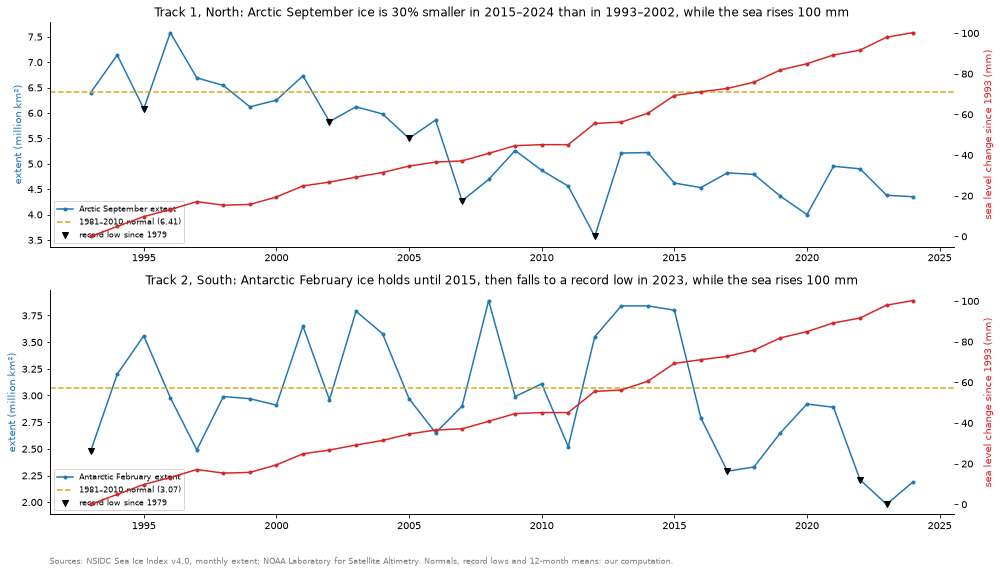

In [17]:
TRACK_TITLES = {
    "N": f"Track 1, North: Arctic September ice is {-stats.loc['Arctic', 'change (%)']:.0f}% smaller in 2015–2024 than in 1993–2002, "
         f"while the sea rises {sea_change.loc[2024]:.0f} mm",
    "S": f"Track 2, South: Antarctic February ice holds until {stats.loc['Antarctic', 'last year at or above the normal']}, "
         f"then falls to a record low in {stats.loc['Antarctic', 'lowest year']}, while the sea rises {sea_change.loc[2024]:.0f} mm",
}
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, h in zip(axes, "NS"):
    s = month_ice[h]
    ax.plot(s.index, s.values, color="tab:blue", marker="o", markersize=3, label=f"{NAME[h]} {MONTH_NAME[h]} extent")
    ax.axhline(month_normal[h], color="goldenrod", linestyle="--", label=f"1981–2010 normal ({month_normal[h]:.2f})")
    lows = s[record_low[h]]
    ax.scatter(lows.index, lows.values, color="black", marker="v", zorder=3, label="record low since 1979")
    ax.set_ylabel("extent (million km²)", color="tab:blue")
    ax.legend(fontsize=8, loc="lower left")
    sea_ax = ax.twinx()
    sea_ax.plot(sea_change.index, sea_change.values, color="tab:red", marker="o", markersize=3)
    sea_ax.set_ylabel("sea level change since 1993 (mm)", color="tab:red")
    ax.set_title(TRACK_TITLES[h])
source_note(axes[1], "Sources: NSIDC Sea Ice Index v4.0, monthly extent; NOAA Laboratory for Satellite Altimetry. "
                     "Normals, record lows and 12-month means: our computation.")
plt.tight_layout()

## 10. Globe polygons

[NSIDC monthly extent polygons](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_extent/), [1981–2010 median ice edges](https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/shapefiles/shp_median/)

The globe draws each year's ice from NSIDC's monthly extent polygons (the same monthly data as section 9) and the 1981–2010 median ice edge as the yellow normal line, as on [5382](https://svs.gsfc.nasa.gov/5382/). NSIDC ships them in its polar stereographic projection, and the globe needs longitude and latitude, so the code below:

- simplifies each polygon by 15 km and drops pieces under 10,000 km², which are too small to see on the record label,
- closes a polygon that goes round the pole along the pole, and splits everything at the 180° meridian,
- rounds coordinates to 0.1° (about 11 km, below the 15 km simplification).

The check converts the result back to an equal-area projection and compares its area with NSIDC's extent.

In [18]:
SIMPLIFY_M = 15_000
MIN_PART_M2 = 10_000 * 1e6
WORLD = box(-180, -90, 180, 90)
POLE_LAT = {"N": 90, "S": -90}
EQUAL_AREA = {"N": 6931, "S": 6932}  # EASE-Grid 2.0 North and South


def lonlat_ring(coords, to_lonlat, pole_lat):
    x, y = np.asarray(coords)[:, :2].T
    lon, lat = to_lonlat.transform(x, y)
    lon = np.degrees(np.unwrap(np.radians(lon)))
    points = list(zip(lon, lat))
    if abs(lon[-1] - lon[0]) > 180:  # the ring goes round the pole: close it along the pole
        points += [(lon[-1], pole_lat), (lon[0], pole_lat)]
    return Polygon(points).buffer(0)


def wrap(geom):
    """Fold a polygon drawn on unwrapped longitudes back into -180..180."""
    parts = [affinity.translate(geom, xoff=k).intersection(WORLD) for k in (-720, -360, 0, 360, 720)]
    return unary_union([p for p in parts if not p.is_empty])


def lonlat_polygon(poly, to_lonlat, pole_lat):
    shell = lonlat_ring(poly.exterior.coords, to_lonlat, pole_lat)
    holes = [lonlat_ring(r.coords, to_lonlat, pole_lat) for r in poly.interiors if Polygon(r).area >= MIN_PART_M2]
    if holes:
        shell = shell.difference(unary_union([affinity.translate(g, xoff=k) for g in holes for k in (-360, 0, 360)]))
    return wrap(shell)


def polygonal(geom):
    """Only the areas of a geometry, as one MultiPolygon. Unions and rounding can leave stray points and lines
    beside the polygons (a GeometryCollection), which the globe cannot draw."""
    parts = [g for g in getattr(geom, "geoms", [geom]) if g.geom_type in ("Polygon", "MultiPolygon")]
    return MultiPolygon([p for g in parts for p in getattr(g, "geoms", [g])])


def ice_polygon(h, year):
    name = f"extent_{h}_{year}{MONTH[h]:02d}_polygon_v4.0.zip"
    path = download(f"shapefiles/{name}", f"{NSIDC}/{POLE[h]}/monthly/shapefiles/shp_extent/{MONTH_DIR[h]}/{name}")
    g = gpd.read_file(path)
    to_lonlat = Transformer.from_crs(g.crs, 4326, always_xy=True)
    parts = [p for p in g.geometry.simplify(SIMPLIFY_M).explode(index_parts=False) if p.area >= MIN_PART_M2]
    return polygonal(shapely.set_precision(unary_union([lonlat_polygon(p, to_lonlat, POLE_LAT[h]) for p in parts]), 0.1))


def normal_edge(h):
    name = f"median_extent_{h}_{MONTH[h]:02d}_1981-2010_polyline_v4.0.zip"
    path = download(f"shapefiles/{name}", f"{NSIDC}/{POLE[h]}/monthly/shapefiles/shp_median/{name}")
    g = gpd.read_file(path)
    to_lonlat = Transformer.from_crs(g.crs, 4326, always_xy=True)
    segments = []
    for line in g.geometry.simplify(SIMPLIFY_M).explode(index_parts=False):
        x, y = np.asarray(line.coords)[:, :2].T
        lon, lat = to_lonlat.transform(x, y)
        cuts = np.where(np.abs(np.diff(lon)) > 180)[0] + 1  # split where the line crosses 180°
        segments += [LineString(zip(a, b)) for a, b in zip(np.split(lon, cuts), np.split(lat, cuts)) if len(a) > 1]
    return shapely.set_precision(MultiLineString(segments), 0.1)


globe = {}
for h in "NS":
    features = [{"type": "Feature", "properties": {"kind": "normal", "period": "1981-2010"},
                 "geometry": mapping(normal_edge(h))}]
    for year in TRACK_YEARS:
        features.append({"type": "Feature",
                         "properties": {"kind": "ice", "year": year, "extent_million_km2": float(month_ice[h].loc[year])},
                         "geometry": mapping(ice_polygon(h, year))})
    globe[h] = {"type": "FeatureCollection", "features": features}


def area_check(h):
    ice = gpd.GeoDataFrame.from_features(globe[h]["features"][1:], crs=4326)
    area = ice.to_crs(EQUAL_AREA[h]).area / 1e12
    diff = (area.values / ice["extent_million_km2"].values - 1) * 100
    assert (ice.geom_type == "MultiPolygon").all(), f"{NAME[h]}: not every year is a MultiPolygon"
    return {"polygons": len(ice), "valid": bool(ice.is_valid.all()), "area vs extent, mean (%)": diff.mean(),
            "worst (%)": diff[np.abs(diff).argmax()], "size (KB)": len(json.dumps(globe[h], separators=(",", ":"))) / 1024}


pd.DataFrame({NAME[h]: area_check(h) for h in "NS"}).T.round(2)

,polygons,valid,"area vs extent, mean (%)",worst (%),size (KB)
Arctic,32,True,-0.694148,2.762244,231.44043
Antarctic,32,True,-0.309778,-3.087584,284.399414


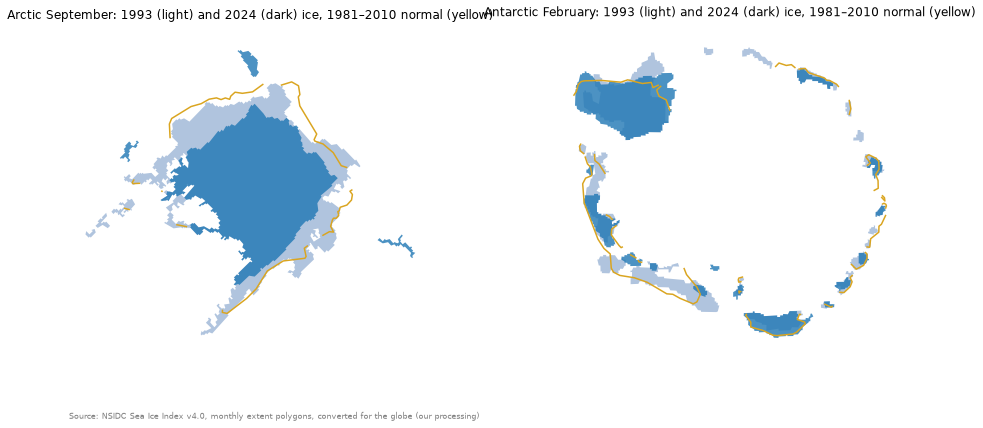

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, h in zip(axes, "NS"):
    collection = gpd.GeoDataFrame.from_features(globe[h]["features"], crs=4326).to_crs(EQUAL_AREA[h])
    ice = collection[collection["kind"] == "ice"]
    ice[ice["year"] == TRACK_YEARS[0]].plot(ax=ax, color="lightsteelblue", label=str(TRACK_YEARS[0]))
    ice[ice["year"] == 2024].plot(ax=ax, color="tab:blue", alpha=0.8, label="2024")
    collection[collection["kind"] == "normal"].plot(ax=ax, color="goldenrod", linewidth=1.5)
    month = "September" if h == "N" else "February"
    ax.set_title(f"{NAME[h]} {month}: {TRACK_YEARS[0]} (light) and 2024 (dark) ice, 1981–2010 normal (yellow)")
    ax.set_axis_off()
source_note(axes[0], "Source: NSIDC Sea Ice Index v4.0, monthly extent polygons, converted for the globe (our processing)")
plt.tight_layout()

## 11. Export

Writes the album's data to `data/glacier/tracks/` ([data-guide.md](../docs/data-guide.md)):

- one CSV per track, one row per year: ice extent, its normal, whether the year is a record low, and sea level,
- one GeoJSON per pole with the yearly ice polygons and the normal line, for the globe,
- `tracks.json` with the message, sources and credit of every track.

Files from an earlier export that no track uses any more are removed.

In [20]:
def iso(years, month):
    return [f"{y}-{month:02d}-01" for y in years]


def downloaded(*names):
    return date.fromtimestamp(min((RAW / n).stat().st_mtime for n in names)).isoformat()


def page(page_id, quoted):
    assert quoted in message(page_id), f"not on {page_id}: {quoted}"
    return {"svsId": page_id, "svsUrl": f"https://svs.gsfc.nasa.gov/{page_id}/", "message": quoted}


SEA_PAGE = page(5235, "As the planet warms and polar ice melts, our global average sea level is rising.")
ICE_PAGE = {
    "N": page(5382, "Every summer the Arctic ice cap melts down to what scientists call its \"minimum\" before colder weather begins to cause ice cover to increase."),
    "S": page(5064, "This visualization shows the daily Antarctic sea ice and seasonal land cover change progressing through time"),
}
NSIDC_SOURCE = {"source": "NSIDC Sea Ice Index, Version 4 (G02135)", "sourceUrl": "https://nsidc.org/data/g02135",
                "version": "4.0", "doi": "https://doi.org/10.7265/a98x-0f50",
                "license": "Open access; cite as asked on the dataset page",
                "credit": "Fetterer, F., et al. Sea Ice Index, Version 4. NSIDC.",
                "substitute": "EIC names JAXA AMSR2 but gives no link; its grids need a JAXA G-Portal login and start "
                              "in 2012. NSIDC is the source of the numbers EIC quotes on 5382."}
STAR_SOURCE = {"source": "NOAA Laboratory for Satellite Altimetry, global mean sea level (annual signals removed)",
               "sourceUrl": STAR_PAGE, "downloadUrl": STAR_URL, "version": "not versioned (updated in place)",
               "license": "Open access; acknowledgment required",
               "credit": "Altimetry data are provided by NOAA Laboratory for Satellite Altimetry.",
               "substitute": "EIC cites NASA GSFC Global Mean Sea Level v5.1 (doi:10.5067/GMSLM-TJ151), which needs "
                             "an Earthdata login. NOAA uses the same altimeter missions. Only the change since 1993 is used.",
               "downloaded": downloaded(STAR_FILE)}
GEOJSON = {"N": "arctic_september_sea_ice_extent.geojson", "S": "antarctic_february_sea_ice_extent.geojson"}
CSV = {"N": "arctic_sea_ice_and_global_sea_level.csv", "S": "antarctic_sea_ice_and_global_sea_level.csv"}
TITLE = {"N": "North", "S": "South"}


def sources(h):
    csv_name = f"{h}_{MONTH[h]:02d}_extent_v4.0.csv"
    shapes = [f"shapefiles/extent_{h}_{y}{MONTH[h]:02d}_polygon_v4.0.zip" for y in TRACK_YEARS]
    shapes.append(f"shapefiles/median_extent_{h}_{MONTH[h]:02d}_1981-2010_polyline_v4.0.zip")
    return [
        {**NSIDC_SOURCE, "downloadUrl": f"{NSIDC}/{POLE[h]}/monthly/data/{csv_name}", "downloaded": downloaded(f"monthly/{csv_name}")},
        {**NSIDC_SOURCE, "downloadUrl": f"{NSIDC}/{POLE[h]}/monthly/shapefiles/", "downloaded": downloaded(*shapes)},
        STAR_SOURCE,
    ]


def track(h):
    data = pd.DataFrame({"date": iso(TRACK_YEARS, MONTH[h]), "extent_million_km2": month_ice[h].values,
                         "normal_1981_2010_million_km2": round(month_normal[h], 3),
                         "record_low": record_low[h].astype(int).values,
                         "sea_level_change_mm": sea_change.round(1).values})
    entry = {
        "file": CSV[h], "title": TITLE[h], "pages": [ICE_PAGE[h], SEA_PAGE],
        "note": f"Ours: the {MONTH_NAME[h]} average of every year, the month of the {NAME[h]} minimum, against its 1981–2010 "
                "normal, with the global mean sea level (12-month mean centered on September 1, change since 1993). "
                "Sea ice is shown as a sign of polar ice melt; its amount does not drive the sea level values.",
        "sources": sources(h), "visuals": [GEOJSON[h]],
        "units": {"extent_million_km2": "million km²",
                  "normal_1981_2010_million_km2": "million km², 1981–2010 average of the same month",
                  "record_low": "1 when the extent is lower than every earlier year since 1979",
                  "sea_level_change_mm": "mm, change since 1993"},
        "timeRange": [data["date"].iloc[0], data["date"].iloc[-1]],
    }
    return entry, data


TRACKS.mkdir(parents=True, exist_ok=True)
tracks, written = [], {"tracks.json"}
for h in "NS":
    entry, data = track(h)
    data.to_csv(TRACKS / entry["file"], index=False)
    (TRACKS / GEOJSON[h]).write_text(json.dumps(globe[h], separators=(",", ":")))
    tracks.append(entry)
    written |= {entry["file"], GEOJSON[h]}
(TRACKS / "tracks.json").write_text(json.dumps(tracks, indent=2, ensure_ascii=False) + "\n")

for stale in [p for p in TRACKS.iterdir() if p.name not in written]:
    stale.unlink()
assert {p.name for p in TRACKS.iterdir()} == written
pd.DataFrame([{"file": p.name, "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(TRACKS.iterdir())])

,file,KB
0,antarctic_february_sea_ice_extent.geojson,284.4
1,antarctic_sea_ice_and_global_sea_level.csv,1.0
2,arctic_sea_ice_and_global_sea_level.csv,1.0
3,arctic_september_sea_ice_extent.geojson,231.4
4,tracks.json,6.7


## Next steps

- Map each track's ice and sea level to sound in the `music` feature (issue #17): one year is one beat, D minor, a different main instrument per track.
- Draw the yearly ice, the normal line, the record-low line and the rising water on the globe, in sync with the sound.